# 04 — Đóng gói và xác minh bộ dữ liệu cuối

Notebook độc lập, không gọi src/. Đọc kết quả notebook 03, đối soát với dữ liệu sạch và split, xuất bộ dữ liệu trước huấn luyện.

1. Kiểm tra provenance và schema.
2. Xác minh membership train/val, fold và test.
3. Định nghĩa feature contract.
4. Đóng gói train/val/test, đối soát nội dung đã lưu.
5. Kiểm tra chất lượng trên development, bàn giao.

Không tạo lại split, không tạo/thay đặc trưng, không scaling, encoding, statistical imputation hay huấn luyện. Không chọn đặc trưng dựa trên holdout.

Output: data/processed/datasets/. CSV báo cáo: reports/tables/ khi EXPORT_REPORTS=True. Không sửa nguồn, notebooks cũ, data/raw/ hoặc data/splits/.

## 1. Nguồn và provenance
Đọc feature_manifest.json từ notebook 03; xác minh fingerprint tất cả artifact đặc trưng, tám bảng sạch và ba file split. Dừng nếu nguồn không khớp, tránh đóng gói dữ liệu từ nhiều phiên bản.

train trong notebook này là 80% development; val là 20% holdout cuối cùng; test là tập Kaggle không nhãn. Các tên này khác với application_train_features, vốn chứa cả development và holdout.

In [1]:
import hashlib
import json
import os
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
from IPython.display import display

def locate_project_root(cwd: Path) -> Path:
    override = os.getenv("HOME_CREDIT_ROOT")
    if override:
        root = Path(override).expanduser().resolve()
        if not (root / "data" / "raw").is_dir():
            raise FileNotFoundError(f"HOME_CREDIT_ROOT không chứa data/raw/: {root}")
        return root
    for folder in (cwd.resolve(), *cwd.resolve().parents):
        if (folder / "data" / "raw").is_dir():
            return folder
    raise FileNotFoundError("Không tìm thấy data/raw/. Đặt HOME_CREDIT_ROOT.")

def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def labeled_source_sha256(df: pd.DataFrame) -> str:
    array = df.sort_values(ID_COL)[[ID_COL, TARGET_COL]].to_numpy(dtype="int64")
    return hashlib.sha256(np.ascontiguousarray(array).tobytes()).hexdigest()

ROOT = locate_project_root(Path.cwd())
CLEAN_DIR = ROOT / "data" / "processed"
FEATURE_DIR = CLEAN_DIR / "features"
SPLIT_DIR = ROOT / "data" / "splits"
OUTPUT_DIR = CLEAN_DIR / "datasets"
REPORT_DIR = ROOT / "reports" / "tables"
ID_COL, TARGET_COL, FOLD_COL = "SK_ID_CURR", "TARGET", "fold"
EXPORT_REPORTS = True
REBUILD_OUTPUTS = False  # Chỉ bật khi chủ động ghi lại artifact dẫn xuất.
DATASET_VERSION = "datasets_v1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 14)
plt.rcParams.update({"figure.figsize": (9, 4), "figure.dpi": 110})


def save_report(frame: pd.DataFrame, name: str) -> None:
    if EXPORT_REPORTS:
        REPORT_DIR.mkdir(parents=True, exist_ok=True)
        frame.to_csv(REPORT_DIR / name, index=False, encoding="utf-8-sig")


feature_manifest_path = FEATURE_DIR / "feature_manifest.json"
feature_manifest = json.loads(feature_manifest_path.read_text(encoding="utf-8"))
assert feature_manifest["version"] == "features_v1", "Cần xem lại contract khi feature version thay đổi"
assert set(feature_manifest["artifacts"]) >= {"application_train_features.parquet", "application_test_features.parquet"}
feature_hashes = {}
for name, entry in feature_manifest["artifacts"].items():
    path = FEATURE_DIR / name
    feature_hashes[name] = file_sha256(path)
    assert feature_hashes[name] == entry["sha256"], name
    metadata = pq.ParquetFile(path).metadata
    assert metadata.num_rows == entry["n_rows"] and metadata.num_columns == entry["n_columns"]
clean_hashes = {}
for table, expected in feature_manifest["source_sha256"].items():
    clean_hashes[table] = file_sha256(CLEAN_DIR / f"{table}.parquet")
    assert clean_hashes[table] == expected, table
split_hashes = {}
for name, expected in feature_manifest["split_sha256"].items():
    split_hashes[name] = file_sha256(SPLIT_DIR / name)
    assert split_hashes[name] == expected, name
feature_manifest_hash = file_sha256(feature_manifest_path)
print(f"Đã xác minh {len(feature_hashes)} artifact, {len(clean_hashes)} bảng sạch và {len(split_hashes)} file split.")

Đã xác minh 8 artifact, 8 bảng sạch và 3 file split.


## 2. Membership, nhãn và 5 fold
Kiểm tra ID duy nhất, không thiếu, không giao nhau giữa development/holdout/test; phủ đủ tập có nhãn. Nhãn đối chiếu với application sạch. Không xem quan hệ feature–TARGET trên holdout.

fold=k xác định phần validation nội bộ của development; fold!=k là phần dùng fit trong lượt CV đó. val.parquet bên dưới là holdout cuối cùng, không phải một fold CV.

In [2]:
train_membership = pd.read_parquet(SPLIT_DIR / "train.parquet")
val_membership = pd.read_parquet(SPLIT_DIR / "val.parquet")
split_metadata = json.loads((SPLIT_DIR / "train_val_metadata.json").read_text(encoding="utf-8"))
clean_labels = pd.read_parquet(CLEAN_DIR / "application_train.parquet", columns=[ID_COL, TARGET_COL])
feature_labels = pd.read_parquet(FEATURE_DIR / "application_train_features.parquet", columns=[ID_COL, TARGET_COL])
test_ids = pd.read_parquet(FEATURE_DIR / "application_test_features.parquet", columns=[ID_COL])
clean_test_ids = pd.read_parquet(CLEAN_DIR / "application_test.parquet", columns=[ID_COL])
assert list(train_membership.columns) == [ID_COL, FOLD_COL]
assert list(val_membership.columns) == [ID_COL]
for frame in [train_membership, val_membership, clean_labels, feature_labels, test_ids]:
    assert frame.notna().all().all() and frame[ID_COL].is_unique
    assert pd.api.types.is_integer_dtype(frame[ID_COL])
assert set(feature_labels[TARGET_COL]) == {0, 1}
pd.testing.assert_frame_equal(
    clean_labels.sort_values(ID_COL).reset_index(drop=True),
    feature_labels.sort_values(ID_COL).reset_index(drop=True),
)
pd.testing.assert_frame_equal(test_ids, clean_test_ids)
assert labeled_source_sha256(clean_labels) == split_metadata["source_sha256"]
train_ids, val_ids, labeled_ids = set(train_membership[ID_COL]), set(val_membership[ID_COL]), set(feature_labels[ID_COL])
assert not train_ids & val_ids and train_ids | val_ids == labeled_ids
assert not labeled_ids & set(test_ids[ID_COL])
assert len(train_membership) == split_metadata["n_train"]
assert len(val_membership) == split_metadata["n_val"]
assert len(feature_labels) == split_metadata["n_full"]
assert abs(len(val_ids) / len(labeled_ids) - split_metadata["holdout_ratio"]) <= 1 / len(labeled_ids)
assert split_metadata["n_folds"] == 5
assert pd.api.types.is_integer_dtype(train_membership[FOLD_COL])
assert set(train_membership[FOLD_COL]) == set(range(5))
development_labels = train_membership.merge(feature_labels, on=ID_COL, how="left", validate="one_to_one")
assert development_labels[TARGET_COL].notna().all()
base_counts = development_labels[TARGET_COL].value_counts().reindex([0, 1])
fold_rows = []
for fold in range(5):
    y = development_labels.loc[development_labels[FOLD_COL].eq(fold), TARGET_COL]
    counts = y.value_counts().reindex([0, 1], fill_value=0)
    assert counts.gt(0).all()
    assert ((counts - base_counts / 5).abs() <= 1).all()
    fold_rows.append({"fold": fold, "n_fold_train": len(development_labels)-len(y), "n_fold_valid": len(y),
                      "n_positive_fold_valid": int(y.sum()), "positive_rate_fold_valid": float(y.mean())})
fold_summary_df = pd.DataFrame(fold_rows)
assert fold_summary_df.n_fold_valid.sum() == len(train_membership)
assert fold_summary_df.n_fold_valid.max() - fold_summary_df.n_fold_valid.min() <= 1
save_report(fold_summary_df, "dataset_cv_validation.csv")
display(fold_summary_df)
print(f"Membership: train={len(train_ids):,}, val={len(val_ids):,}, test={len(test_ids):,}; không giao nhau.")

,fold,n_fold_train,n_fold_valid,n_positive_fold_valid,positive_rate_fold_valid
0,0,196806,49202,3972,0.080728
1,1,196806,49202,3972,0.080728
2,2,196806,49202,3972,0.080728
3,3,196807,49201,3972,0.080730
4,4,196807,49201,3972,0.080730


Membership: train=246,008, val=61,503, test=48,744; không giao nhau.


## 3. Feature contract
Duy trì đúng thứ tự predictor từ schema nguồn. Loại SK_ID_CURR, TARGET và fold khỏi X. Kiểm tra không còn khóa bảng phụ trong predictor.

categorical_columns ở contract là các cột vật lý dạng chuỗi; integer codes, binary và ordinal vẫn được phân loại numeric về mặt lưu trữ. Đây chưa phải quyết định encoding theo mô hình. Không suy diễn kiểu cột từ một sample.

In [3]:
train_schema = pq.read_schema(FEATURE_DIR / "application_train_features.parquet")
test_schema = pq.read_schema(FEATURE_DIR / "application_test_features.parquet")
assert TARGET_COL in train_schema.names and TARGET_COL not in test_schema.names
assert FOLD_COL not in train_schema.names and FOLD_COL not in test_schema.names
assert [name for name in train_schema.names if name != TARGET_COL] == test_schema.names
assert all(train_schema.field(name).type == test_schema.field(name).type for name in test_schema.names)
excluded_columns = [ID_COL, TARGET_COL, FOLD_COL]
predictor_columns = [name for name in train_schema.names if name not in excluded_columns]
assert len(predictor_columns) == len(set(predictor_columns)) == feature_manifest["n_predictors"]
assert not any(name.startswith("SK_ID_") for name in predictor_columns)
categorical_columns, numeric_columns = [], []
for name in predictor_columns:
    dtype = train_schema.field(name).type
    if pa.types.is_string(dtype) or pa.types.is_large_string(dtype):
        categorical_columns.append(name)
    elif pa.types.is_integer(dtype) or pa.types.is_floating(dtype) or pa.types.is_boolean(dtype):
        numeric_columns.append(name)
    else:
        raise TypeError(f"Kiểu predictor chưa được hỗ trợ: {name}={dtype}")
assert set(categorical_columns) | set(numeric_columns) == set(predictor_columns)
feature_contract = {
    "version": DATASET_VERSION,
    "identifier_column": ID_COL, "target_column": TARGET_COL, "fold_column": FOLD_COL,
    "predictor_columns": predictor_columns, "n_predictors": len(predictor_columns),
    "categorical_columns": categorical_columns, "numeric_columns": numeric_columns,
    "excluded_from_X": excluded_columns,
    "physical_types": {name: str(train_schema.field(name).type) for name in predictor_columns},
    "dataset_columns": {
        "train": [ID_COL, TARGET_COL, FOLD_COL, *predictor_columns],
        "val": [ID_COL, TARGET_COL, *predictor_columns],
        "test": [ID_COL, *predictor_columns],
    },
    "semantics": {
        "train": "development only, five fixed stratified CV folds",
        "val": "final holdout, no tuning or feature selection",
        "test": "unlabeled Kaggle test",
        "categorical": "physical text columns only; numeric-coded categories remain numeric in this contract",
        "missing": "preserve existing missing values and structural history counts; no learned imputation",
        "preprocessing": "fit encoders, imputers and any scaler on fold-training only",
    },
}
schema_report_df = pd.DataFrame([
    {"feature": name, "position_in_X": i, "physical_type": feature_contract["physical_types"][name],
     "storage_group": "text" if name in categorical_columns else "numeric"}
    for i,name in enumerate(predictor_columns)
])
save_report(schema_report_df, "dataset_feature_schema.csv")
print(f"Contract: {len(predictor_columns)} predictor; {len(numeric_columns)} numeric và {len(categorical_columns)} text.")
display(schema_report_df.head(12))

Contract: 180 predictor; 164 numeric và 16 text.


,feature,position_in_X,physical_type,storage_group
0,NAME_CONTRACT_TYPE,0,large_string,text
1,CODE_GENDER,1,large_string,text
2,FLAG_OWN_CAR,2,large_string,text
3,FLAG_OWN_REALTY,3,large_string,text
4,CNT_CHILDREN,4,int64,numeric
5,AMT_INCOME_TOTAL,5,double,numeric
6,AMT_CREDIT,6,double,numeric
7,AMT_ANNUITY,7,double,numeric
8,AMT_GOODS_PRICE,8,double,numeric
9,NAME_TYPE_SUITE,9,large_string,text


## 4. Đóng gói và đối soát
Đọc một tập tại một thời điểm. Join one_to_one theo membership, giữ đúng thứ tự membership. Không fit hoặc biến đổi predictor.

train.parquet: ID + TARGET + fold + predictor. val.parquet: ID + TARGET + predictor. test.parquet: ID + predictor. Output nằm trong data/processed/datasets/, khác các file membership data/splits/.

Output đã có chỉ được tái sử dụng nếu khớp nội dung. REBUILD_OUTPUTS=True cho phép ghi lại artifact dẫn xuất, không sửa đầu vào.
Đọc/ghi theo batch 8.192 dòng và đối soát từng row group. Mỗi cột development được đọc riêng khi tính số giá trị duy nhất; không sampling. Batch size là một phần cách ghi output: nếu đổi, cần chủ động REBUILD_OUTPUTS=True. Dừng nếu thứ tự nguồn không khớp membership thay vì âm thầm sắp xếp lại.

Với row group nguồn rộng, đọc thêm theo nhóm 8 cột rồi ghép batch. Cách này đánh đổi thêm lượt đọc để giảm buffer giải mã đồng thời; không thay giá trị hoặc sampling.

REBUILD_OUTPUTS=True cũng cho phép ghi lại file .inprogress của lần export gián đoạn. Mặc định dừng để kiểm tra, không tự sửa đầu vào.

Batch được gom vào buffer nhỏ riêng trước khi chuyển sang pandas; writer dùng page nhỏ để giới hạn RAM. Các lựa chọn lưu trữ Parquet không phải encoding đầu vào mô hình.


In [4]:
def assemble_dataset(features: pd.DataFrame, membership: pd.DataFrame, split: str,
                     predictors: list[str]) -> pd.DataFrame:
    assert split in {"train", "val", "test"}
    assert features[ID_COL].notna().all() and features[ID_COL].is_unique
    assert membership[ID_COL].notna().all() and membership[ID_COL].is_unique
    assert set(features[ID_COL]) == set(membership[ID_COL]), "Thiếu hoặc thừa khách hàng so với membership"
    assert FOLD_COL not in features and "_merge" not in features
    expected_source = [ID_COL, *predictors] if split == "test" else [ID_COL, TARGET_COL, *predictors]
    assert list(features.columns) == expected_source
    expected_membership = [ID_COL, FOLD_COL] if split == "train" else [ID_COL]
    assert list(membership.columns) == expected_membership
    assembled = membership.merge(features, on=ID_COL, how="left", sort=False, validate="one_to_one", indicator=True)
    assert assembled.pop("_merge").eq("both").all()
    pd.testing.assert_series_equal(assembled[ID_COL], membership[ID_COL].reset_index(drop=True))
    if split == "train":
        order = [ID_COL, TARGET_COL, FOLD_COL, *predictors]
    elif split == "val":
        order = [ID_COL, TARGET_COL, *predictors]
    else:
        order = [ID_COL, *predictors]
    return assembled.loc[:, order]


def iter_feature_batches(source: Path, batch_size: int = 8_192):
    # File notebook 03 có row group rộng. Chỉ batch theo hàng vẫn giữ buffer giải mã
    # cho cả 180 cột; đọc thêm theo nhóm cột để giới hạn đỉnh RAM.
    with pq.ParquetFile(source) as reader:
        columns = reader.schema_arrow.names
        for group in range(reader.num_row_groups):
            n_rows = reader.metadata.row_group(group).num_rows
            for offset in range(0, n_rows, batch_size):
                pieces = []
                for start in range(0, len(columns), 8):
                    table = reader.read_row_group(group, columns=columns[start:start+8], use_threads=False)
                    window = table.slice(offset, min(batch_size, n_rows-offset))
                    # take tạo buffer nhỏ riêng, tránh StringArray giữ toàn bộ row group nguồn.
                    compact = window.take(pa.array(np.arange(window.num_rows), type=pa.int64()))
                    piece = compact.to_pandas()
                    pieces.append(piece.reset_index(drop=True))
                    del table, piece, window, compact
                yield pd.concat(pieces, axis=1)
                del pieces
                pa.default_memory_pool().release_unused()


def iter_assembled_dataset(split: str, membership: pd.DataFrame, predictors: list[str]):
    source = FEATURE_DIR / ("application_test_features.parquet" if split == "test" else "application_train_features.parquet")
    lookup = pd.Index(membership[ID_COL])
    seen = 0
    for features in iter_feature_batches(source):
        positions = lookup.get_indexer(features[ID_COL])
        keep = positions >= 0
        if not keep.any():
            continue
        selected = features.loc[keep].reset_index(drop=True)
        selected_membership = membership.iloc[positions[keep]].reset_index(drop=True)
        assembled = assemble_dataset(selected, selected_membership, split, predictors)
        # Đầu vào hiện tại cùng thứ tự ID; dừng nếu nguồn/membership đổi thứ tự.
        expected_ids = membership[ID_COL].iloc[seen:seen+len(assembled)].reset_index(drop=True)
        pd.testing.assert_series_equal(assembled[ID_COL], expected_ids)
        seen += len(assembled)
        yield assembled
        del assembled, selected, selected_membership, features, positions, keep, expected_ids
    assert seen == len(membership), f"Không phủ đủ membership: {split}"


def persist_dataset(split: str, membership: pd.DataFrame, predictors: list[str]) -> dict:
    path = OUTPUT_DIR / f"{split}.parquet"
    expected_columns = feature_contract["dataset_columns"][split]
    expected_schema = pa.schema([
        pa.field(name, pa.int64()) if name == FOLD_COL else train_schema.field(name)
        for name in expected_columns
    ])
    if not path.exists() or REBUILD_OUTPUTS:
        temporary = path.with_suffix(".parquet.inprogress")
        if temporary.exists() and not REBUILD_OUTPUTS:
            raise FileExistsError(f"Output chưa hoàn tất: {temporary}")
        writer = None
        try:
            for assembled in iter_assembled_dataset(split, membership, predictors):
                table = pa.Table.from_pandas(assembled, schema=expected_schema, preserve_index=False)
                if writer is None:
                    writer = pq.ParquetWriter(temporary, table.schema, compression="snappy",
                                             use_dictionary=False, data_page_size=65_536, write_batch_size=256)
                writer.write_table(table)
                del table, assembled
        finally:
            if writer is not None:
                writer.close()
        if writer is None:
            raise ValueError(f"Tập rỗng: {split}")
        del writer
        temporary.replace(path)
        pa.default_memory_pool().release_unused()
    # Mỗi batch ghi thành một row group; đọc lại nguồn theo cùng batch để đối soát chính xác.
    n_rows, group_index = 0, 0
    with pq.ParquetFile(path) as reader:
        assert reader.schema_arrow.names == expected_columns
        for name in predictors:
            assert reader.schema_arrow.field(name).type == train_schema.field(name).type
        for expected in iter_assembled_dataset(split, membership, predictors):
            assert group_index < reader.num_row_groups
            saved = reader.read_row_group(group_index, use_threads=False).to_pandas()
            pd.testing.assert_frame_equal(saved, expected)
            if split != "test":
                labels = labels_by_id.reindex(saved[ID_COL]).reset_index(drop=True)
                pd.testing.assert_series_equal(saved[TARGET_COL], labels)
            if split == "train":
                expected_folds = folds_by_id.reindex(saved[ID_COL]).reset_index(drop=True)
                pd.testing.assert_series_equal(saved[FOLD_COL], expected_folds)
            for name in numeric_columns:
                assert not np.isinf(saved[name].to_numpy(dtype=float)).any(), f"{split}.{name}"
            n_rows += len(saved)
            group_index += 1
            del saved, expected
            pa.default_memory_pool().release_unused()
        assert group_index == reader.num_row_groups
    assert n_rows == len(membership)
    return {"path": f"data/processed/datasets/{path.name}", "sha256": file_sha256(path),
            "n_rows": n_rows, "n_columns": len(expected_columns), "parquet_mib": path.stat().st_size / 1024**2}


def profile_development(path: Path, predictors: list[str]) -> pd.DataFrame:
    rows = []
    with pq.ParquetFile(path) as reader:
        n_rows = reader.metadata.num_rows
        for i, name in enumerate(predictors):
            values = reader.read(columns=[name], use_threads=False).column(0)
            dtype = reader.schema_arrow.field(name).type
            n_missing = values.null_count
            if pa.types.is_floating(dtype):
                is_nan = pc.fill_null(pc.is_nan(values), False)
                n_missing += pc.sum(is_nan).as_py() or 0
                values = pc.if_else(is_nan, pa.scalar(None, type=dtype), values)
                # pandas coi -0.0 và +0.0 là một giá trị; chuẩn hóa chỉ cho thống kê.
                values = pc.if_else(pc.equal(values, 0), pa.scalar(0.0, type=dtype), values)
                del is_nan
            n_unique = pc.count_distinct(values, mode="only_valid").as_py()
            rows.append({"feature": name, "dtype": str(dtype), "n_rows": n_rows,
                         "n_missing": n_missing, "missing_rate": n_missing/n_rows,
                         "n_unique_nonmissing": n_unique, "all_missing": n_unique == 0,
                         "constant_nonmissing": n_unique == 1})
            del values
            pa.default_memory_pool().release_unused()
            if (i + 1) % 30 == 0:
                print(f"[PROFILE] {i+1}/{len(predictors)} cột development", flush=True)
    return pd.DataFrame(rows)

In [5]:
dataset_artifacts, summary_rows = {}, []
labels_by_id = clean_labels.set_index(ID_COL)[TARGET_COL]
folds_by_id = train_membership.set_index(ID_COL)[FOLD_COL]
memberships = {"train": train_membership, "val": val_membership, "test": test_ids}
for split, membership in memberships.items():
    entry = persist_dataset(split, membership, predictor_columns)
    dataset_artifacts[split] = entry
    summary_rows.append({"dataset": split, **{k: entry[k] for k in ["n_rows", "n_columns", "parquet_mib"]},
                         "n_predictors": len(predictor_columns), "has_target": split != "test",
                         "has_fold": split == "train", "content_verified": True})
    print(f"[VERIFIED] {split}: {entry['n_rows']:,} hàng × {entry['n_columns']} cột; predictor không đổi.", flush=True)
dataset_summary_df = pd.DataFrame(summary_rows)
assert dataset_artifacts["train"]["n_rows"] + dataset_artifacts["val"]["n_rows"] == len(feature_labels)
assert dataset_artifacts["test"]["n_rows"] == len(test_ids)
development_profile_df = profile_development(OUTPUT_DIR / "train.parquet", predictor_columns)
save_report(dataset_summary_df, "dataset_packaging_summary.csv")
save_report(development_profile_df, "dataset_development_quality.csv")
display(dataset_summary_df.round(3))


[VERIFIED] train: 246,008 hàng × 183 cột; predictor không đổi.
[VERIFIED] val: 61,503 hàng × 182 cột; predictor không đổi.
[VERIFIED] test: 48,744 hàng × 181 cột; predictor không đổi.
[PROFILE] 30/180 cột development
[PROFILE] 60/180 cột development
[PROFILE] 90/180 cột development
[PROFILE] 120/180 cột development
[PROFILE] 150/180 cột development
[PROFILE] 180/180 cột development


,dataset,n_rows,n_columns,parquet_mib,n_predictors,has_target,has_fold,content_verified
0,train,246008,183,79.378,180,True,True,True
1,val,61503,182,21.897,180,True,False,True
2,test,48744,181,16.196,180,False,False,True


## 5. Chất lượng development và bàn giao
Chỉ mô tả development, không tự loại cột. Một cột có một giá trị không thiếu nhưng có missing vẫn có thể chứa thông tin từ missingness. Không fit median, học category vocabulary hoặc xem tương quan với nhãn holdout.
Thống kê trực tiếp bằng Arrow theo từng cột, dùng chung reader. dtype là kiểu lưu trữ vật lý. NaN/null đều tính là thiếu; -0.0 và +0.0 cùng một mức giá trị trong cardinality. Chỉ chuẩn hóa mảng tạm để thống kê, không sửa dữ liệu.


,value
n_predictors,180
n_text_columns,16
n_numeric_columns,164
n_all_missing_development,0
n_constant_nonmissing_development,0
n_columns_with_missing_development,109
automatic_drop_count,0


,feature,dtype,n_rows,n_missing,missing_rate,n_unique_nonmissing,all_missing,constant_nonmissing
165,CC_UTILIZATION_MEAN_LOAN,double,246008,177205,0.720322,47299,False,False
166,CC_UTILIZATION_MAX,double,246008,177205,0.720322,45200,False,False
167,CC_DPD_MAX,double,246008,176499,0.717452,384,False,False
168,CC_LATEST_BALANCE_SUM,double,246008,176499,0.717452,24520,False,False
169,CC_LATEST_LIMIT_SUM,double,246008,176499,0.717452,174,False,False
143,BUREAU_BB_LATE_RATE_MEAN_LOAN,double,246008,174119,0.707778,8451,False,False
145,BUREAU_BB_LATE_RATE_WEIGHTED,double,246008,174119,0.707778,3347,False,False
141,BUREAU_BB_KNOWN_MONTHS_SUM,double,246008,172224,0.700075,445,False,False
142,BUREAU_BB_LATE_MONTHS_SUM,double,246008,172224,0.700075,150,False,False
140,BUREAU_BB_MONTHS_SUM,double,246008,172224,0.700075,1065,False,False


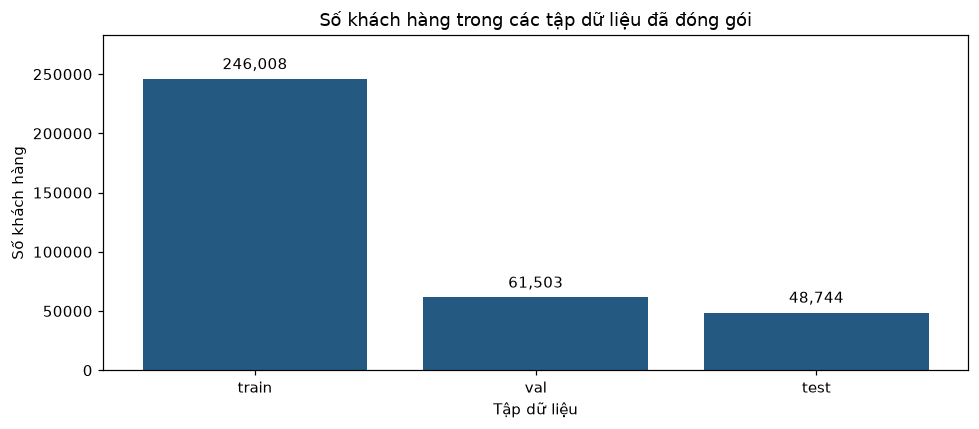

In [6]:
quality_summary_df = pd.DataFrame([{
    "n_predictors": len(development_profile_df),
    "n_text_columns": len(categorical_columns), "n_numeric_columns": len(numeric_columns),
    "n_all_missing_development": int(development_profile_df.all_missing.sum()),
    "n_constant_nonmissing_development": int(development_profile_df.constant_nonmissing.sum()),
    "n_columns_with_missing_development": int(development_profile_df.n_missing.gt(0).sum()),
    "automatic_drop_count": 0,
}])
save_report(quality_summary_df, "dataset_development_quality_summary.csv")
display(quality_summary_df.T.rename(columns={0: "value"}))
display(development_profile_df.sort_values("missing_rate", ascending=False).head(15))
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(dataset_summary_df.dataset, dataset_summary_df.n_rows, color="#245A81")
ax.bar_label(bars, labels=[f"{n:,}" for n in dataset_summary_df.n_rows], padding=4)
ax.set(title="Số khách hàng trong các tập dữ liệu đã đóng gói", xlabel="Tập dữ liệu", ylabel="Số khách hàng")
ax.set_ylim(0, dataset_summary_df.n_rows.max() * 1.15)
fig.tight_layout()
plt.show()

In [7]:
def save_json_verified(value: dict, name: str) -> None:
    path = OUTPUT_DIR / name
    if path.exists() and not REBUILD_OUTPUTS:
        assert json.loads(path.read_text(encoding="utf-8")) == value, f"JSON khác phiên bản: {name}"
    else:
        temporary = path.with_suffix(".json.inprogress")
        if temporary.exists() and not REBUILD_OUTPUTS:
            raise FileExistsError(temporary)
        temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")
        temporary.replace(path)


# Xác minh lại đầu vào sau đóng gói.
assert file_sha256(feature_manifest_path) == feature_manifest_hash
assert all(file_sha256(FEATURE_DIR/name) == digest for name,digest in feature_hashes.items())
assert all(file_sha256(CLEAN_DIR/f"{table}.parquet") == digest for table,digest in clean_hashes.items())
assert all(file_sha256(SPLIT_DIR/name) == digest for name,digest in split_hashes.items())
feature_contract["source_feature_manifest_sha256"] = feature_manifest_hash
save_json_verified(feature_contract, "feature_contract.json")
contract_hash = file_sha256(OUTPUT_DIR / "feature_contract.json")
manifest_path = OUTPUT_DIR / "dataset_manifest.json"
created_at = datetime.now(timezone.utc).isoformat()
if manifest_path.exists() and not REBUILD_OUTPUTS:
    created_at = json.loads(manifest_path.read_text(encoding="utf-8"))["created_at_utc"]
dataset_manifest = {
    "version": DATASET_VERSION, "created_at_utc": created_at,
    "feature_manifest_sha256": feature_manifest_hash,
    "input_feature_sha256": feature_hashes, "input_clean_sha256": clean_hashes,
    "input_split_sha256": split_hashes, "feature_contract_sha256": contract_hash,
    "n_predictors": len(predictor_columns), "artifacts": dataset_artifacts,
    "validation": {"membership_disjoint": True, "label_preserved": True,
                   "fold_preserved": True, "predictor_values_preserved": True,
                   "serialized_content_verified": True, "input_hashes_unchanged": True},
}
save_json_verified(dataset_manifest, "dataset_manifest.json")
print(f"PASS: train={dataset_artifacts['train']['n_rows']:,}, val={dataset_artifacts['val']['n_rows']:,}, test={dataset_artifacts['test']['n_rows']:,}.")
print(f"Contract: {len(predictor_columns)} predictor, không có ID/TARGET/fold; nguồn và split giữ nguyên.")
print(f"Output: {OUTPUT_DIR}; xuất CSV reports/tables/: {EXPORT_REPORTS}")

PASS: train=246,008, val=61,503, test=48,744.
Contract: 180 predictor, không có ID/TARGET/fold; nguồn và split giữ nguyên.
Output: D:\HCMUT\(HK261_CQ) LẬP TRÌNH CHO TRÍ TUỆ NHÂN TẠO VÀ KHOA HỌC DỮ LIỆU (CO3135)_TRẦN HUY\home-credit-risk\data\processed\datasets; xuất CSV reports/tables/: True


## 6. Cách dùng ở giai đoạn huấn luyện sau này

Đọc feature_contract.json và chọn đúng predictor_columns theo thứ tự. Không dùng toàn bộ cột train.parquet làm X vì file có ID, TARGET và fold.

~~~python
contract = json.loads((OUTPUT_DIR / "feature_contract.json").read_text(encoding="utf-8"))
data = pd.read_parquet(OUTPUT_DIR / "train.parquet")
X = data.loc[:, contract["predictor_columns"]]
y = data[contract["target_column"]]
folds = data[contract["fold_column"]]
# Trong mỗi lượt CV k: fit preprocessing trên folds != k, transform folds == k.
~~~

Đây là hướng dẫn, không chạy fit. Dataset giữ chuỗi và missing; encoder/scaler/imputer và xử lý category mới thuộc pipeline mô hình theo fold. Holdout val chỉ dùng sau khi chốt phương án; test không có nhãn. Chưa kiểm chứng chất lượng dự đoán hoặc point-in-time correctness đầy đủ; giới hạn notebook 03 vẫn áp dụng.

Không thay đổi hoặc loại 180 predictor. CSV xuất reports/tables/ khi chạy mặc định, không ghi data/dictionaries/.


### Trạng thái xác minh
Đã chạy tuần tự 7 code cell trên toàn bộ dữ liệu; đọc lại từng row group để đối soát.
Lượt kiểm tra đặt EXPORT_REPORTS=False để chỉ ghi trong data/ và notebooks/. Mặc định xuất CSV vào reports/tables/ và không ghi đè output. Nguồn và split giữ nguyên theo SHA-256.
